H1, mu1 = 12.7
Error de tipo II (beta) para n = 7: 0.5655


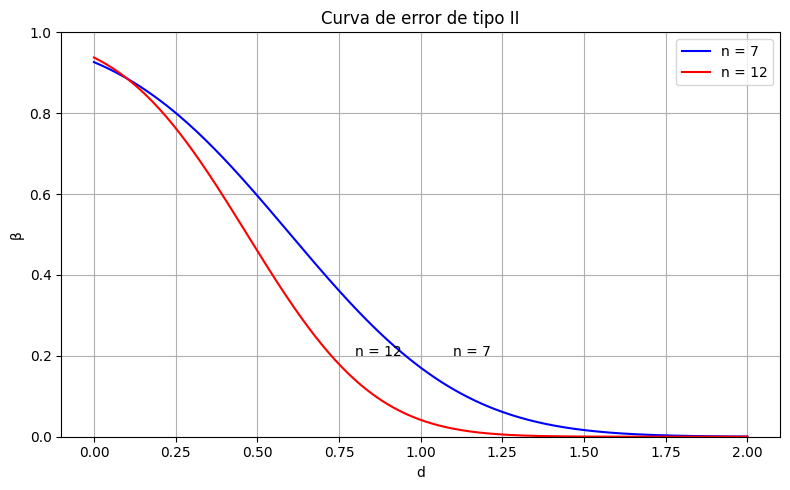

In [3]:
# Ejemplo de t-test y curva de error tipo II

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from scipy.stats import nct
import seaborn as sns

# --- Conversión de mpg a litros/100km ---
cte = 1.60934 / 3.78541  # km/l

# Cargar datos similares a mtcars
# Usamos el dataset 'mpg' de seaborn como aproximación
datos = sns.load_dataset('mpg').dropna()
datos = datos.rename(columns={'mpg': 'mpg', 'cylinders': 'cyl'})

# Convertimos mpg a litros/100km
datos['mpg'] = 100 / (datos['mpg'] * cte)

# Filtramos autos con 6 cilindros
datos_seis_cilindros = datos[datos['cyl'] == 6]
valores = datos_seis_cilindros['mpg'].values

# --- Parámetros del test ---
alpha = 0.05
crit = t.ppf(1 - alpha, df=len(valores) - 1)
mu0 = 11.7
delta = 1.0  # diferencia detectable
s = np.std(valores, ddof=1)
d = delta / s

# --- Cálculo de beta para n = 7 ---
n1 = 7
ncp1 = d * np.sqrt(n1)
beta1 = nct.cdf(crit, df=n1 - 1, loc=0, nc=ncp1)#t.cdf(crit, df=n1 - 1, loc=0, scale=1, nc=ncp1)

print(f'H1, mu1 = {mu0 + delta}')
print(f'Error de tipo II (beta) para n = {n1}: {beta1:.4f}')

# --- Curva de error tipo II ---
xLims = (0, 2)
d_vals = np.linspace(*xLims, 300)

# Curvas para n = 7 y n = 12
n2 = 12
beta_curve_n1 = [nct.cdf(crit, df=n1 - 1, loc=0, scale=1, nc=d * np.sqrt(n1)) for d in d_vals]#[t.cdf(crit, df=n1 - 1, loc=0, scale=1, nc=d * np.sqrt(n1)) for d in d_vals]
beta_curve_n2 = [nct.cdf(crit, df=n2 - 1, loc=0, scale=1, nc=d * np.sqrt(n2)) for d in d_vals]#[t.cdf(crit, df=n2 - 1, loc=0, scale=1, nc=d * np.sqrt(n2)) for d in d_vals]

# --- Gráfico ---
plt.figure(figsize=(8, 5))
plt.plot(d_vals, beta_curve_n1, color='blue', label='n = 7')
plt.plot(d_vals, beta_curve_n2, color='red', label='n = 12')
plt.title('Curva de error de tipo II')
plt.xlabel('d')
plt.ylabel('β')
plt.ylim(0, 1)
plt.text(0.8, 0.2, 'n = 12', fontsize=10)
plt.text(1.1, 0.2, 'n = 7', fontsize=10)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
